# **LABORATORIO 2: REGRESION LINEAL MULTIPLE**
### Predicción del Precio de la Energía Eléctrica
**Objetivo:** El presente laboratorio tiene como objetivo implementar el modelo de Regresión Lineal Múltiple (utilizando el Descenso por el Gradiente y la Ecuación de la Normal) para predecir el **precio actual de la energía eléctrica (`price actual`)**. Para ello, se utilizan múltiples características operativas como la generación de energía a través de distintas fuentes (biomasa, gas, carbón, solar, eólica) y previsiones de carga extraídas del dataset `energy_dataset.csv`.

https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather?select=energy_dataset.csv

LIBRERIAS

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline
# Importamos 'display' para mostrar tablas en Colab
from IPython.display import display


Apertura del dataset usando Pandas

In [2]:
ruta = '/energy_dataset.csv'
df = pd.read_csv(ruta)
print("Dimensiones originales:", df.shape)

Dimensiones originales: (35064, 29)


## 1. Carga y Preprocesamiento de Datos
Para este paso utilizamos la librería **Pandas**. El dataset original presenta una columna de texto temporal y múltiples valores nulos. Para poder entrenar el modelo matemático **sin eliminar ninguna fila ni columna numérica**, procesamos los datos aislando únicamente el texto, rellenando los valores nulos con el promedio de su respectiva columna (y con ceros en el caso de columnas 100% vacías para no perder su dimensionalidad) y finalmente separando nuestra variable objetivo (`y`).

In [3]:
# Excluimos únicamente la columna 'time' porque es texto (fechas) y las matrices matemáticas no multiplican texto.
df_numeric = df.select_dtypes(include=[np.number])

# a) Rellenamos los vacíos normales con el promedio de su respectiva columna
df_numeric = df_numeric.fillna(df_numeric.mean())

# b) Si había columnas 100% vacías, su promedio da error (NaN).
# ¡En lugar de eliminarlas, las rellenamos con 0 para conservar la columna entera!
df_numeric = df_numeric.fillna(0)

# 3. Definimos nuestra variable objetivo 'y' y características 'X'
y = df_numeric['price actual'].values
X_df = df_numeric.drop(['price actual'], axis=1)
X = X_df.values

m = len(y)
n = X.shape[1]
print(f"Cantidad de ejemplos (m): {m}")
print(f"Cantidad de características (n): {n}")

Cantidad de ejemplos (m): 35064
Cantidad de características (n): 27


## 2. Normalización de Características
Dado que las variables del dataset de energía tienen escalas muy diferentes (algunas en decenas y otras en miles), la normalización ajusta los datos para que tengan media 0 y desviación estándar 1. Esto permite que el algoritmo de Descenso por el Gradiente converja mucho más rápido y sin errores.

In [4]:
# Función para normalizar (necesario cuando los valores tienen diferentes magnitudes)
def featureNormalize(X):
    X_norm = X.copy()
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)

    # Si alguna desviación estándar es 0, la cambiamos a 1 para evitar división por cero
    sigma[sigma == 0] = 1

    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma

X_norm, mu, sigma = featureNormalize(X)

# Añadimos la columna de unos a la matriz X (término de intersección)
X_ready = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

In [5]:
print('Media calculada (primeros 5 valores):', mu[:5])
print('Desviación estandar calculada (primeros 5 valores):', sigma[:5])

print('\nEjemplo de las primeras 3 filas de X_norm:')
print(X_norm[:3])

print('\nEjemplo de las primeras 3 filas de X con la columna de unos (X0):')
print(X_ready[:3])

Media calculada (primeros 5 valores): [ 383.51353973  448.0592079     0.         5622.73748787 4256.06574217]
Desviación estandar calculada (primeros 5 valores): [8.53295973e+01 3.54472513e+02 1.00000000e+00 2.20123385e+03
 1.96106948e+03]

Ejemplo de las primeras 3 filas de X_norm:
[[ 7.44014531e-01 -3.35877123e-01  0.00000000e+00 -3.53773175e-01
   2.88074576e-01 -2.59628592e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  4.89058505e-01  1.96883288e-01
  -3.84866075e-01  0.00000000e+00  9.91233037e-01 -8.51513521e-01
  -8.98105447e-01 -8.23775118e-01 -1.46373754e+00  0.00000000e+00
   2.84335883e-01 -8.47639131e-01  0.00000000e+00  3.03747494e-01
  -5.64673488e-01 -7.24305447e-01  1.54363200e-02]
 [ 7.67453057e-01 -3.38698216e-01  0.00000000e+00 -1.93862859e-01
   2.54419470e-01 -2.67246814e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  5.61011795e-01  9.20570949e-02
  -5.16222524e-01  0.00000000e+00  9.91233037e-01 -8.51513521e-01
  -1.

In [6]:

# 1. Hacemos una tabla para ver la Media y Desviación de cada columna
df_stats = pd.DataFrame({
    'Media (mu)': mu,
    'Desv. Est. (sigma)': sigma
}, index=X_df.columns)

print("--- Estadísticas de Normalización (Primeras 5 columnas) ---")
display(df_stats.head()) # .head() muestra solo las primeras 5 filas

# 2. Hacemos una tabla para ver cómo quedó nuestra matriz X lista
# Le ponemos nombre a la columna de unos y recuperamos los nombres de las demás
columnas_ready = ['X0 (Intersección)'] + list(X_df.columns)
df_x_ready = pd.DataFrame(X_ready, columns=columnas_ready)

print("\n--- Primeras 5 filas de los datos normalizados listos para entrenar ---")
display(df_x_ready.head())

--- Estadísticas de Normalización (Primeras 5 columnas) ---


,Media (mu),Desv. Est. (sigma)
generation biomass,383.513540,85.329597
generation fossil brown coal/lignite,448.059208,354.472513
generation fossil coal-derived gas,0.000000,1.000000
generation fossil gas,5622.737488,2201.233848
generation fossil hard coal,4256.065742,1961.069479



--- Primeras 5 filas de los datos normalizados listos para entrenar ---


,X0 (Intersección),generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead
0,1.0,0.744015,-0.335877,0.0,-0.353773,0.288075,-2.596286,0.0,0.0,0.0,...,-0.823775,-1.463738,0.0,0.284336,-0.847639,0.0,0.303747,-0.564673,-0.724305,0.015436
1,1.0,0.767453,-0.338698,0.0,-0.193863,0.254419,-2.672468,0.0,0.0,0.0,...,-0.823180,-1.483665,0.0,0.132444,-0.848235,0.0,0.121143,-0.822399,-0.943657,-0.121375
2,1.0,0.755734,-0.352804,0.0,-0.347867,0.165692,-2.691514,0.0,0.0,0.0,...,-0.823180,-1.463738,0.0,-0.001083,-0.853004,0.0,-0.005420,-1.131278,-1.304066,-0.174047
3,1.0,0.638541,-0.547459,0.0,-0.594547,-0.063774,-2.634377,0.0,0.0,0.0,...,-0.823180,-1.563376,0.0,-0.070493,-0.856580,0.0,-0.100815,-1.321307,-1.620737,-0.520179
4,1.0,0.521349,-0.736472,0.0,-0.678137,-0.212163,-2.710559,0.0,0.0,0.0,...,-0.827943,-1.603232,0.0,-0.164802,-0.852408,0.0,-0.192118,-1.507853,-1.844244,-0.784225


## 3. Funciones de Costo y Descenso por el Gradiente
A continuación, se definen las funciones matemáticas base. La **Función de Costo** calculará el error entre la predicción y el valor real, mientras que el **Descenso por el Gradiente** actualizará los parámetros (thetas) iterativamente para minimizar dicho error.

In [7]:
# Función de Costo
def computeCostMulti(X, y, theta):
    m = len(y)
    J = (1 / (2 * m)) * np.sum(np.square(np.dot(X, theta) - y))
    return J

# Descenso por el Gradiente
def gradientDescentMulti(X, y, theta, alpha, num_iters):
    m = len(y)
    J_history = []
    theta = theta.copy()

    for i in range(num_iters):
        # Actualización de theta
        theta = theta - (alpha / m) * np.dot(X.T, (np.dot(X, theta) - y))
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

## 4. Entrenamiento del Modelo y Gráfica de Convergencia
Aplicamos el Descenso por el Gradiente utilizando los datos preprocesados. Graficaremos el historial de la función de costo para verificar que el modelo aprende correctamente, lo cual se evidencia si la curva desciende y se estabiliza.

Iniciando el entrenamiento...
¡Entrenamiento finalizado!
Costo final minimizado: 43.30


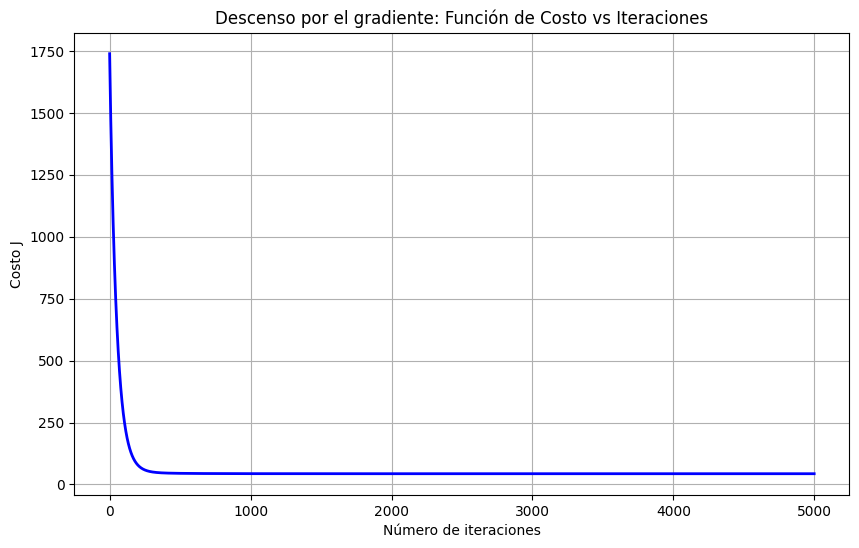

In [8]:
# Hiperparámetros (puedes jugar con el valor de alpha)
alpha = 0.01
num_iters = 5000

# Inicializar theta en ceros (n + 1 valores)
theta_initial = np.zeros(X_ready.shape[1])

# Entrenar el modelo
print("Iniciando el entrenamiento...")
theta_opt, J_history = gradientDescentMulti(X_ready, y, theta_initial, alpha, num_iters)
print("¡Entrenamiento finalizado!")
print(f"Costo final minimizado: {J_history[-1]:.2f}")

# Graficar la convergencia de la función de costo
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(J_history)), J_history, lw=2, color='blue')
plt.xlabel('Número de iteraciones')
plt.ylabel('Costo J')
plt.title('Descenso por el gradiente: Función de Costo vs Iteraciones')
plt.grid(True)
plt.show()

## 5. Predicción con el Modelo Entrenado
Para comprobar la eficacia de nuestro modelo, tomamos la primera fila de datos de nuestro dataset, la normalizamos y la pasamos por el modelo para que nos prediga el precio de la energía. Luego, lo comparamos con el precio real registrado en esa misma fila.

In [9]:
# 1. Tomamos los datos de la primera fila del dataset original (nuestro array de prueba)
X_array = X[0].copy()

# 2. Normalizamos este array usando el 'mu' y 'sigma' que calculamos en la Celda 2
X_array_norm = (X_array - mu) / sigma

# 3. Le agregamos el "1" al principio (que es el término de intersección X0)
X_array_ready = np.append(1, X_array_norm)

# 4. Hacemos la predicción multiplicando nuestro array por los thetas óptimos
precio_predicho_gd = np.dot(X_array_ready, theta_opt)

print(f"El precio predicho (Descenso por el Gradiente) es: {precio_predicho_gd:.2f}")
print(f"El precio real en el dataset era: {y[0]:.2f}")

El precio predicho (Descenso por el Gradiente) es: 58.06
El precio real en el dataset era: 65.41


## 6. Resolución mediante la Ecuación de la Normal
Como método de validación final, resolvemos el mismo problema utilizando la Ecuación de la Normal. Este método analítico permite encontrar los valores óptimos de $\theta$ directamente sin necesidad de normalizar los datos ni iterar con una tasa de aprendizaje (usando la pseudo-inversa de la matriz para evitar singularidades).

In [10]:
# --- Celda 6: Ecuación de la Normal (CORREGIDA) ---

def normalEqn(X, y):
    # Usamos np.linalg.pinv (pseudo-inversa) para evitar el error de Matriz Singular
    theta = np.dot(np.dot(np.linalg.pinv(np.dot(X.T, X)), X.T), y)
    return theta

# Preparamos los datos
X_sin_normalizar_ready = np.concatenate([np.ones((m, 1)), X], axis=1)

# Calculamos los thetas exactos
theta_normal = normalEqn(X_sin_normalizar_ready, y)

# Predecimos
X_array_normal = np.append(1, X[0])
precio_predicho_normal = np.dot(X_array_normal, theta_normal)

print(f"Precio predicho (Ecuación de la Normal): {precio_predicho_normal:.2f}")
print(f"Precio real en el dataset: {y[0]:.2f}")

Precio predicho (Ecuación de la Normal): 57.82
Precio real en el dataset: 65.41
